# Customer Segmentation using  clustering 

## Import Libraries 

In [1]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

In [2]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Patch

In [3]:
# Modles
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

In [4]:
# Load the dataset
df = pd.read_csv('Dataset_3.csv')
print("First Five Rows")
df.head()

First Five Rows


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Data Preprocessing 

In [5]:
print("\nDataset Info: ")
df.info()


Dataset Info: 
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [6]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


In [7]:
print("Initial dataset shape: ",df.shape)

Initial dataset shape:  (200, 5)


In [8]:
df_cleaned = df.drop(columns=['CustomerID'])
print("Cleaned dataset shape: ",df.shape)

Cleaned dataset shape:  (200, 5)


# EDA

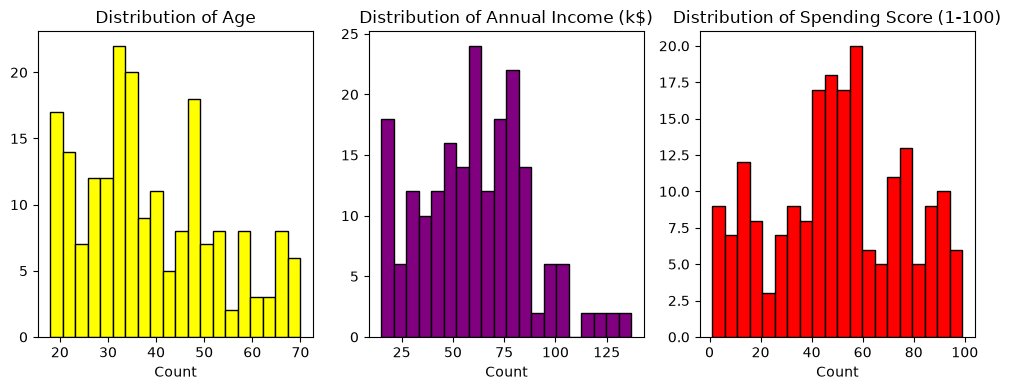

In [9]:
# Histrograms
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

axes[0].hist(df['Age'], bins=20, color='yellow', edgecolor='black')
axes[0].set_title('Distribution of Age')
axes[0].set_xlabel('Count')

axes[1].hist(df['Annual Income (k$)'], bins=20, color='purple', edgecolor='black')
axes[1].set_title('Distribution of Annual Income (k$)')
axes[1].set_xlabel('Count')

axes[2].hist(df['Spending Score (1-100)'], bins=20, color='red', edgecolor='black')
axes[2].set_title('Distribution of Spending Score (1-100)')
axes[2].set_xlabel('Count')

plt.tight_layout()

plt.savefig("Histrograms",
            dpi=300, 
            bbox_inches="tight")

plt.show()

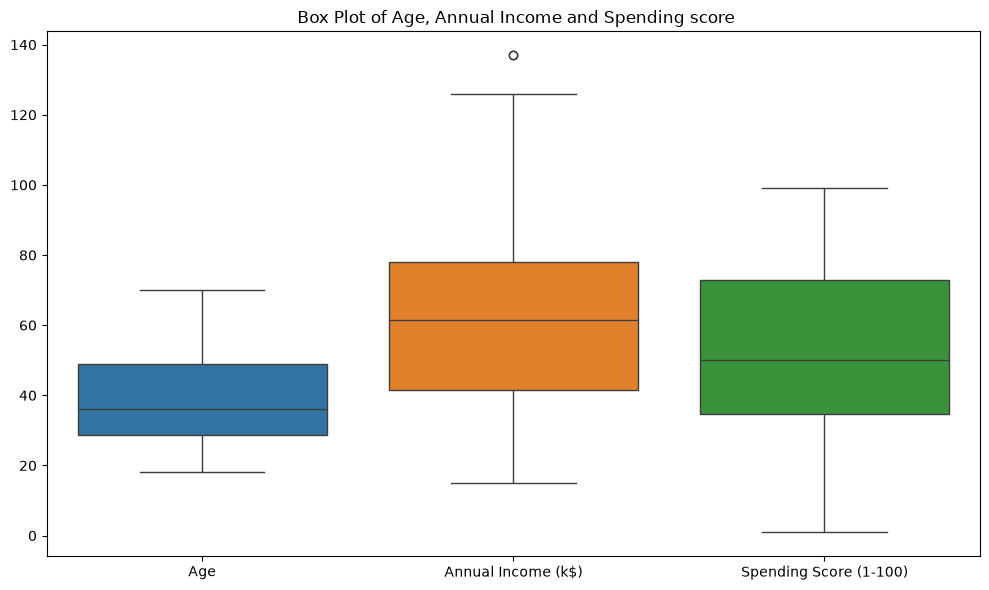

In [10]:
# Box plots 
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']])
plt.title(' Box Plot of Age, Annual Income and Spending score')
plt.tight_layout()

plt.savefig("boxplot",
            dpi=300,
            bbox_inches="tight")

plt.show()

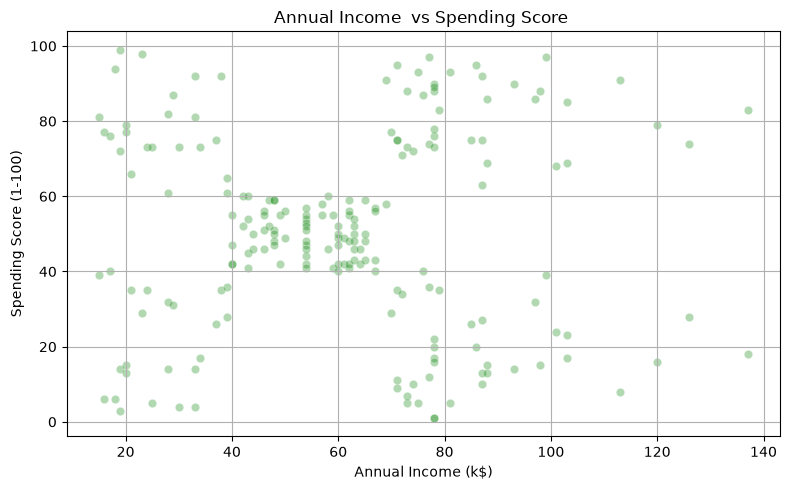

In [11]:
# Scatterplot

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', data=df, alpha=0.3, color='green')
plt.title('Annual Income  vs Spending Score ')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.tight_layout()
plt.grid(True)
plt.tight_layout()

plt.savefig("Annual Income vs Spending Score",
            dpi=300,
            bbox_inches="tight")

plt.show()

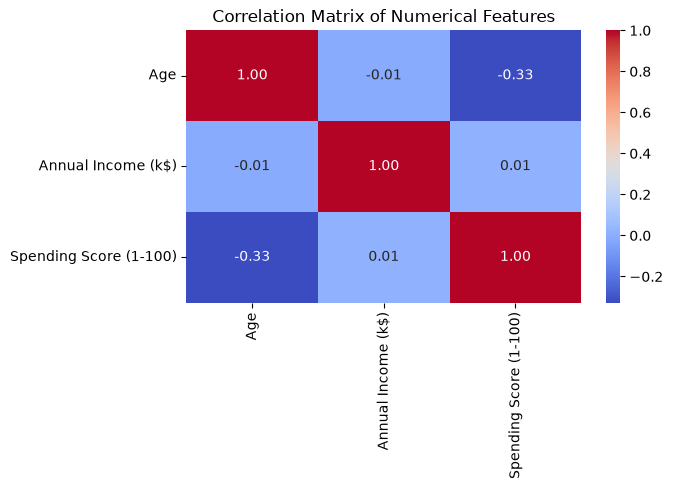

In [12]:
# Heatmap
plt.figure(figsize=(7, 5))
numerical_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()

plt.savefig("Correlation Matrix of Numerical Features", 
            dpi=300, 
            bbox_inches="tight")

plt.show()

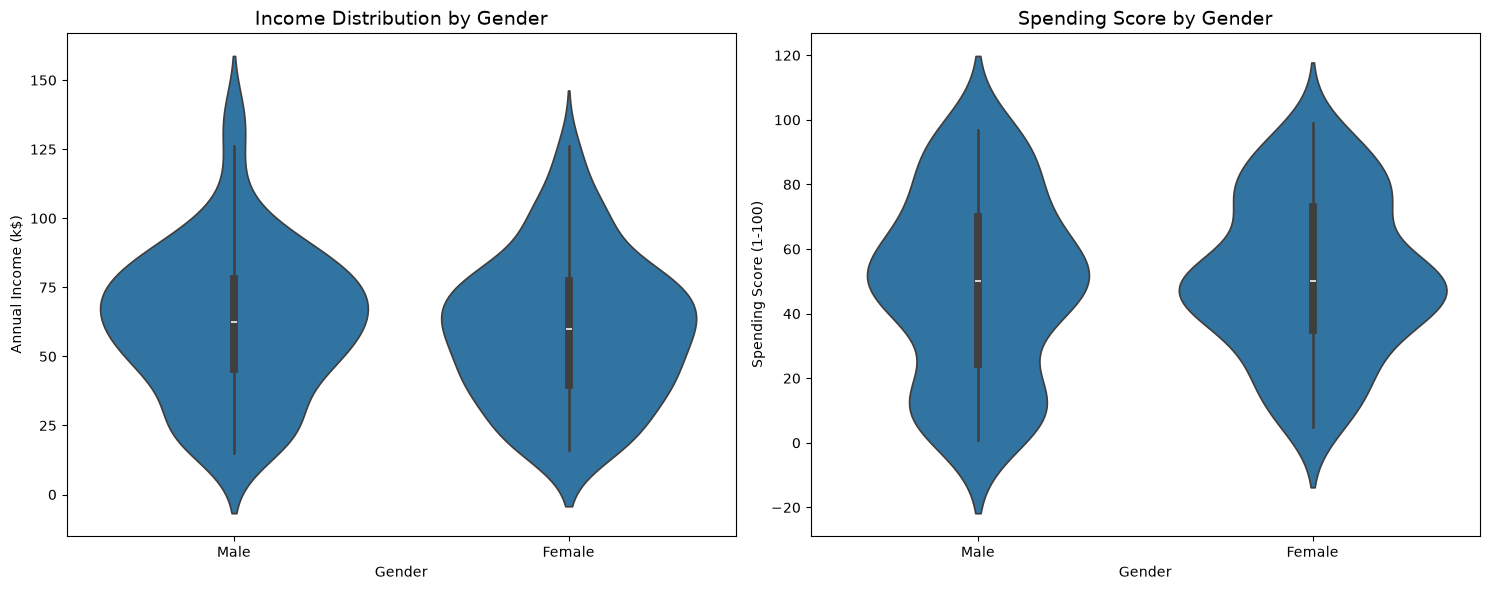

In [13]:
# Violinplot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Income distribution by gender
sns.violinplot(data=df, x='Gender', y='Annual Income (k$)', ax=axes[0])
axes[0].set_title('Income Distribution by Gender', fontsize=14)

# Spending score by gender
sns.violinplot(data=df, x='Gender', y='Spending Score (1-100)', ax=axes[1])
axes[1].set_title('Spending Score by Gender', fontsize=14)
plt.tight_layout()

plt.savefig("violinplot", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

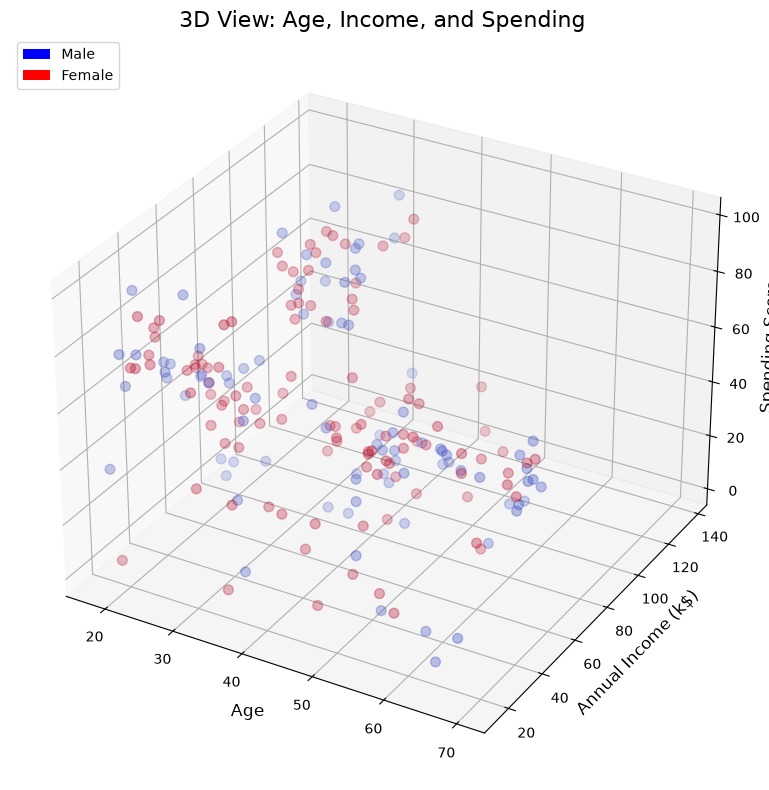

In [14]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df['Age'], df['Annual Income (k$)'], df['Spending Score (1-100)'],
                     c=df['Gender'].map({'Male': 0, 'Female': 1}), 
                     cmap='coolwarm', s=50, alpha=0.6)

ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Annual Income (k$)', fontsize=12)
ax.set_zlabel('Spending Score', fontsize=12)
ax.set_title('3D View: Age, Income, and Spending', fontsize=16)

# Add legend
legend_elements = [Patch(facecolor='blue', label='Male'),
                   Patch(facecolor='red', label='Female')]
ax.legend(handles=legend_elements, loc='upper left')
plt.tight_layout()

plt.savefig("3D  desing ", 
            dpi=300, 
            bbox_inches="tight")

plt.show()

# Clustering|

In [15]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
print("Features selected for clustering:")
print(X.head())

Features selected for clustering:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [16]:
# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier interpretation
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("Before scaling (mean, std):")
print(f"Mean: {X.mean().values}")
print(f"Std: {X.std().values}")

print("\nAfter scaling (mean, std):")
print(f"Mean: {X_scaled_df.mean().values}")
print(f"Std: {X_scaled_df.std().values}")

Before scaling (mean, std):
Mean: [60.56 50.2 ]
Std: [26.26472117 25.82352167]

After scaling (mean, std):
Mean: [-2.13162821e-16 -1.46549439e-16]
Std: [1.00250941 1.00250941]


### Find Optimal Number of Clusters

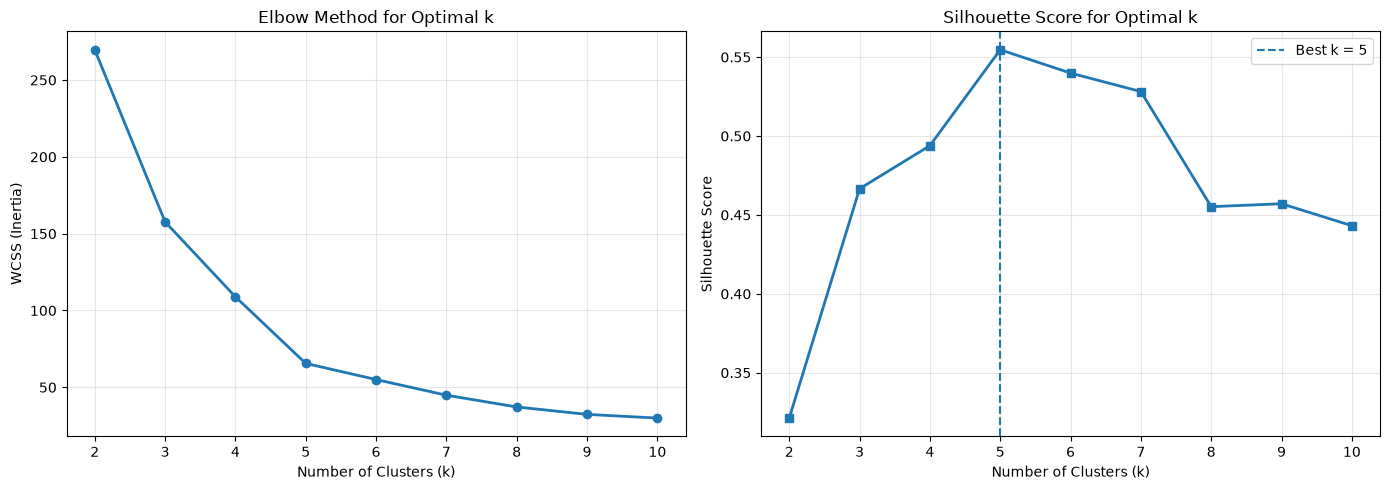

Best number of clusters based on silhouette score: 5


In [42]:
import warnings
warnings.filterwarnings('ignore')

# Calculate WCSS and silhouette scores
wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, kmeans.labels_)
    )

# Find the best k using the silhouette score
best_k = list(k_range)[np.argmax(silhouette_scores)]

# Plot both graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method
axes[0].plot(k_range, wcss, marker="o", linewidth=2)
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("WCSS (Inertia)")
axes[0].set_title("Elbow Method for Optimal k")
axes[0].grid(True, alpha=0.3)

# Silhouette Score
axes[1].plot(
    k_range, silhouette_scores,
    marker="s", linewidth=2
)
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score for Optimal k")
axes[1].grid(True, alpha=0.3)

# Highlight the best k
axes[1].axvline(
    best_k, linestyle="--",
    label=f"Best k = {best_k}"
)
axes[1].legend()

plt.tight_layout()
plt.savefig("Elbow_and_Silhouette.png", dpi=300, bbox_inches="tight")
plt.show()

print("Best number of clusters based on silhouette score:", best_k)

In [20]:
print(f"Optimal number of clusters based on silhouette score: {best_k}")

Optimal number of clusters based on silhouette score: 5


# Apply Kmeans Clustering

In [43]:
import warnings
warnings.filterwarnings('ignore')

# Choose optimal k 
optimal_k = 5

# Apply K-means
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)



# Apply Agglomerative Clustering

In [39]:
agg_model = AgglomerativeClustering(n_clusters=5)

agg_labels = agg_model.fit_predict(X_scaled)

# Save cluster labels
df['Agglomerative_Cluster'] = agg_labels



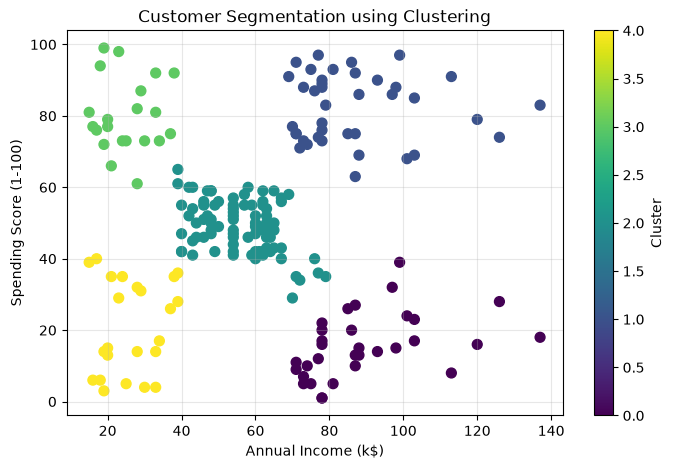

In [44]:
# Visualize customer segments
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=agg_labels,
    cmap='viridis',
    s=50
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using Clustering')
plt.colorbar(label='Cluster')
plt.grid(alpha=0.3)
plt.savefig("Clustering", 
            dpi=300, 
            bbox_inches="tight")
plt.show()


In [41]:
summary = df.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].mean()
print(summary)

print("\nCluster Sizes:")
print(df['Cluster'].value_counts().sort_index())

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043

Cluster Sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [38]:
print('Customer Segmentation Results')
print('1. Cluster 0 → Medium income, medium spending (Average customers)')
print('2. Cluster 1 → High income, high spending (Premium customers)')
print('3. Cluster 2 → Low income, high spending (High-spending low-income customers)')
print('4. Cluster 3 → High income, low spending (Careful / conservative customers)')
print('5. Cluster 4 → Low income, low spending (Budget customers)')

Customer Segmentation Results
1. Cluster 0 → Medium income, medium spending (Average customers)
2. Cluster 1 → High income, high spending (Premium customers)
3. Cluster 2 → Low income, high spending (High-spending low-income customers)
4. Cluster 3 → High income, low spending (Careful / conservative customers)
5. Cluster 4 → Low income, low spending (Budget customers)
